# DAY 39 : TIME INTELLIGENCE AND SALES TREND ANALYSIS

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("superstore.csv" , encoding="latin1")
df.shape

(9994, 14)

In [7]:
df.head()

,Order ID,Order Date,Customer Name,Segment,Country,City,State,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,CA-2016-152156,11-08-2016,Claire Gute,Consumer,United States,Henderson,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,CA-2016-152156,11-08-2016,Claire Gute,Consumer,United States,Henderson,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,CA-2016-138688,06-12-2016,Darrin Van Huff,Corporate,United States,Los Angeles,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,US-2015-108966,10-11-2015,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,US-2015-108966,10-11-2015,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       9994 non-null   object 
 1   Order Date     9994 non-null   object 
 2   Customer Name  9994 non-null   object 
 3   Segment        9994 non-null   object 
 4   Country        9994 non-null   object 
 5   City           9994 non-null   object 
 6   State          9994 non-null   object 
 7   Region         9994 non-null   object 
 8   Category       9994 non-null   object 
 9   Sub-Category   9994 non-null   object 
 10  Sales          9994 non-null   float64
 11  Quantity       9994 non-null   int64  
 12  Discount       9994 non-null   float64
 13  Profit         9994 non-null   float64
dtypes: float64(3), int64(1), object(10)
memory usage: 1.1+ MB


In [11]:
df.describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [12]:
df.duplicated().sum()

1

In [13]:
df.isnull().sum()

Order ID         0
Order Date       0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Region           0
Category         0
Sub-Category     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [16]:
df.columns.tolist()

['Order ID',
 'Order Date',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Region',
 'Category',
 'Sub-Category',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [17]:
df["Order Date"].min()

'01-01-2017'

In [18]:
df["Order Date"].max()

'9/30/2017'

In [19]:
df["Sales"].sum()

2297200.8603000003

In [20]:
df["Sales"].mean()

229.85800083049833

In [23]:
# 1. Inspect duplicate records
print("Duplicate Records:")
display(df[df.duplicated(keep=False)])

# 2. Inspect date formats
print("\nSample Order Dates:")
display(df["Order Date"].sample(15, random_state=42))

# 3. Check unique order dates
print("\nUnique Order Dates:", df["Order Date"].nunique())

# 4. Check unique order IDs
print("\nUnique Order IDs:", df["Order ID"].nunique())

# 5. Check negative or zero sales
print("\nNon-positive Sales Records:",
      (df["Sales"] <= 0).sum())

Duplicate Records:


,Order ID,Order Date,Customer Name,Segment,Country,City,State,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
3405,US-2014-150119,4/23/2014,Laurel Beltran,Home Office,United States,Columbus,Ohio,East,Furniture,Chairs,281.372,2,0.3,-12.0588
3406,US-2014-150119,4/23/2014,Laurel Beltran,Home Office,United States,Columbus,Ohio,East,Furniture,Chairs,281.372,2,0.3,-12.0588



Sample Order Dates:


3125    06-11-2015
1441    12/19/2017
4510    11-10-2016
39      12/27/2015
4509     5/23/2017
1599    11/19/2017
7363    11/28/2016
9951    06-01-2017
500      5/30/2016
4847     6/25/2014
4568    11-08-2015
2758    03-11-2016
6220    10/20/2016
7729     9/26/2016
713      5/19/2017
Name: Order Date, dtype: object


Unique Order Dates: 1237

Unique Order IDs: 5009

Non-positive Sales Records: 0


In [26]:
# 1. REMOVE DUPLICATE RECORDS

print("Rows Before Cleaning:", df.shape[0])

df = df.drop_duplicates().copy()

print("Rows After Cleaning:", df.shape[0])
print("Remaining Duplicates:", df.duplicated().sum())


# 2. STANDARDIZE DATE FORMAT

df["Order Date"] = (
    df["Order Date"]
    .astype(str)
    .str.replace("/", "-", regex=False)
)

# Convert to datetime (US format: Month-Day-Year)
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
)

print("\nDate Data Type:", df["Order Date"].dtype)

print("Starting Date:", df["Order Date"].min())
print("Ending Date:", df["Order Date"].max())


# 3. EXTRACT DATE FEATURES

df["Order_Year"] = df["Order Date"].dt.year

df["Order_Month"] = df["Order Date"].dt.month_name()

df["Month_Number"] = df["Order Date"].dt.month

df["Quarter"] = df["Order Date"].dt.quarter

df["Year_Month"] = df["Order Date"].dt.to_period("M").astype(str)

df["Day_Name"] = df["Order Date"].dt.day_name()

df["Day_Number"] = df["Order Date"].dt.day


# 4. CREATE A DATE DIMENSION TABLE

date_dim = pd.DataFrame({
    "Date": pd.date_range(
        start=df["Order Date"].min(),
        end=df["Order Date"].max(),
        freq="D"
    )
})

date_dim["Year"] = date_dim["Date"].dt.year

date_dim["Month"] = date_dim["Date"].dt.month_name()

date_dim["Month_Number"] = date_dim["Date"].dt.month

date_dim["Quarter"] = date_dim["Date"].dt.quarter

date_dim["Year_Month"] = (
    date_dim["Date"].dt.to_period("M").astype(str)
)

date_dim["Day_Name"] = date_dim["Date"].dt.day_name()

date_dim["Day_Number"] = date_dim["Date"].dt.day

date_dim["Is_Weekend"] = (
    date_dim["Date"].dt.dayofweek.isin([5, 6])
)


# 5. FINAL VALIDATION

print("\n========== FINAL VALIDATION ==========")

print("Updated Dataset Shape:", df.shape)

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Date Data Type:", df["Order Date"].dtype)

print("Unique Years:", sorted(df["Order_Year"].unique()))

print("Unique Quarters:", sorted(df["Quarter"].unique()))

print("Date Dimension Shape:", date_dim.shape)

print("\nUpdated Dataset Preview:")

display(
    df[[
        "Order Date",
        "Order_Year",
        "Order_Month",
        "Month_Number",
        "Quarter",
        "Year_Month",
        "Day_Name"
    ]].head(10)
)

print("\nDate Dimension Preview:")

display(date_dim.head(10))

Rows Before Cleaning: 9993
Rows After Cleaning: 9993
Remaining Duplicates: 0

Date Data Type: datetime64[ns]
Starting Date: 2014-01-03 00:00:00
Ending Date: 2017-12-30 00:00:00

========== FINAL VALIDATION ==========
Updated Dataset Shape: (9993, 21)
Missing Values: 0
Duplicate Rows: 0
Date Data Type: datetime64[ns]
Unique Years: [2014, 2015, 2016, 2017]
Unique Quarters: [1, 2, 3, 4]
Date Dimension Shape: (1458, 9)

Updated Dataset Preview:


,Order Date,Order_Year,Order_Month,Month_Number,Quarter,Year_Month,Day_Name
0,2016-11-08,2016,November,11,4,2016-11,Tuesday
1,2016-11-08,2016,November,11,4,2016-11,Tuesday
2,2016-06-12,2016,June,6,2,2016-06,Sunday
3,2015-10-11,2015,October,10,4,2015-10,Sunday
4,2015-10-11,2015,October,10,4,2015-10,Sunday
5,2014-06-09,2014,June,6,2,2014-06,Monday
6,2014-06-09,2014,June,6,2,2014-06,Monday
7,2014-06-09,2014,June,6,2,2014-06,Monday
8,2014-06-09,2014,June,6,2,2014-06,Monday
9,2014-06-09,2014,June,6,2,2014-06,Monday



Date Dimension Preview:


,Date,Year,Month,Month_Number,Quarter,Year_Month,Day_Name,Day_Number,Is_Weekend
0,2014-01-03,2014,January,1,1,2014-01,Friday,3,False
1,2014-01-04,2014,January,1,1,2014-01,Saturday,4,True
2,2014-01-05,2014,January,1,1,2014-01,Sunday,5,True
3,2014-01-06,2014,January,1,1,2014-01,Monday,6,False
4,2014-01-07,2014,January,1,1,2014-01,Tuesday,7,False
5,2014-01-08,2014,January,1,1,2014-01,Wednesday,8,False
6,2014-01-09,2014,January,1,1,2014-01,Thursday,9,False
7,2014-01-10,2014,January,1,1,2014-01,Friday,10,False
8,2014-01-11,2014,January,1,1,2014-01,Saturday,11,True
9,2014-01-12,2014,January,1,1,2014-01,Sunday,12,True


In [27]:
# 1. CREATE DAILY SALES SUMMARY

daily_sales = (
    df.groupby("Order Date")["Sales"]
    .sum()
    .reset_index()
)

daily_sales.columns = ["Date", "Daily_Sales"]


# 2. MERGE DAILY SALES WITH DATE DIMENSION

time_df = date_dim.merge(
    daily_sales,
    on="Date",
    how="left"
)

time_df["Daily_Sales"] = time_df["Daily_Sales"].fillna(0)


# 3. CALCULATE MTD SALES

time_df["MTD_Sales"] = (
    time_df.groupby("Year_Month")["Daily_Sales"]
    .cumsum()
)


# 4. CALCULATE QTD SALES

time_df["QTD_Sales"] = (
    time_df.groupby(["Year", "Quarter"])["Daily_Sales"]
    .cumsum()
)


# 5. CALCULATE YTD SALES

time_df["YTD_Sales"] = (
    time_df.groupby("Year")["Daily_Sales"]
    .cumsum()
)


# 6. MONTHLY SALES SUMMARY

monthly_sales = (
    time_df.groupby(
        ["Year", "Month_Number", "Year_Month"]
    )["Daily_Sales"]
    .sum()
    .reset_index()
)

monthly_sales = monthly_sales.sort_values(
    ["Year", "Month_Number"]
).reset_index(drop=True)

monthly_sales.rename(
    columns={"Daily_Sales": "Monthly_Sales"},
    inplace=True
)


# 7. PREVIOUS YEAR MONTHLY SALES

monthly_sales["Previous_Year_Sales"] = (
    monthly_sales["Monthly_Sales"].shift(12)
)


# 8. YEAR-OVER-YEAR GROWTH

monthly_sales["YoY_Growth_%"] = (
    (
        monthly_sales["Monthly_Sales"]
        - monthly_sales["Previous_Year_Sales"]
    )
    / monthly_sales["Previous_Year_Sales"]
) * 100

monthly_sales["YoY_Growth_%"] = (
    monthly_sales["YoY_Growth_%"].replace(
        [np.inf, -np.inf], np.nan
    )
)


# 9. BUSINESS VALIDATION

print("========== TIME INTELLIGENCE VALIDATION ==========")

print("Total Daily Records:", len(time_df))

print("Total Monthly Records:", len(monthly_sales))

print("Total Sales:", round(df["Sales"].sum(), 2))

print("Daily Sales Reconciliation:",
      np.isclose(
          time_df["Daily_Sales"].sum(),
          df["Sales"].sum()
      ))

print("Monthly Sales Reconciliation:",
      np.isclose(
          monthly_sales["Monthly_Sales"].sum(),
          df["Sales"].sum()
      ))


# 10. DISPLAY DAILY TIME INTELLIGENCE

print("\nDAILY MTD, QTD AND YTD SALES:")

display(
    time_df[
        [
            "Date",
            "Daily_Sales",
            "MTD_Sales",
            "QTD_Sales",
            "YTD_Sales"
        ]
    ].head(15)
)


# 11. DISPLAY MONTHLY SALES AND YOY GROWTH

print("\nMONTHLY SALES AND YOY ANALYSIS:")

display(monthly_sales.head(20))


# 12. TOP 5 MONTHS BY SALES

print("\nTOP 5 MONTHS BY SALES:")

display(
    monthly_sales.nlargest(5, "Monthly_Sales")[
        ["Year_Month", "Monthly_Sales"]
    ]
)


# 13. YEARLY SALES SUMMARY

yearly_sales = (
    monthly_sales.groupby("Year")["Monthly_Sales"]
    .sum()
    .reset_index()
)

print("\nYEARLY SALES SUMMARY:")

display(yearly_sales)


# 14. FINAL BUSINESS METRICS

print("\n========== FINAL BUSINESS SUMMARY ==========")

print(
    "Highest Revenue Month:",
    monthly_sales.loc[
        monthly_sales["Monthly_Sales"].idxmax(),
        "Year_Month"
    ]
)

print(
    "Highest Revenue Year:",
    yearly_sales.loc[
        yearly_sales["Monthly_Sales"].idxmax(),
        "Year"
    ]
)

print(
    "Average Monthly Sales:",
    round(monthly_sales["Monthly_Sales"].mean(), 2)
)

print(
    "Average YoY Growth:",
    round(monthly_sales["YoY_Growth_%"].mean(), 2),
    "%"
)

========== TIME INTELLIGENCE VALIDATION ==========
Total Daily Records: 1458
Total Monthly Records: 48
Total Sales: 2296919.49
Daily Sales Reconciliation: True
Monthly Sales Reconciliation: True

DAILY MTD, QTD AND YTD SALES:


,Date,Daily_Sales,MTD_Sales,QTD_Sales,YTD_Sales
0,2014-01-03,16.448,16.448,16.448,16.448
1,2014-01-04,288.060,304.508,304.508,304.508
2,2014-01-05,19.536,324.044,324.044,324.044
3,2014-01-06,4407.100,4731.144,4731.144,4731.144
4,2014-01-07,87.158,4818.302,4818.302,4818.302
5,2014-01-08,0.000,4818.302,4818.302,4818.302
6,2014-01-09,40.544,4858.846,4858.846,4858.846
7,2014-01-10,54.830,4913.676,4913.676,4913.676
8,2014-01-11,9.940,4923.616,4923.616,4923.616
9,2014-01-12,0.000,4923.616,4923.616,4923.616



MONTHLY SALES AND YOY ANALYSIS:


,Year,Month_Number,Year_Month,Monthly_Sales,Previous_Year_Sales,YoY_Growth_%
0,2014,1,2014-01,14236.8950,NaN,NaN
1,2014,2,2014-02,4519.8920,NaN,NaN
2,2014,3,2014-03,55691.0090,NaN,NaN
3,2014,4,2014-04,28013.9730,NaN,NaN
4,2014,5,2014-05,23648.2870,NaN,NaN
5,2014,6,2014-06,34595.1276,NaN,NaN
6,2014,7,2014-07,33946.3930,NaN,NaN
7,2014,8,2014-08,27909.4685,NaN,NaN
8,2014,9,2014-09,81777.3508,NaN,NaN
9,2014,10,2014-10,31453.3930,NaN,NaN



TOP 5 MONTHS BY SALES:


,Year_Month,Monthly_Sales
46,2017-11,118447.8250
35,2016-12,96999.0430
44,2017-09,87866.6520
47,2017-12,83829.3188
8,2014-09,81777.3508



YEARLY SALES SUMMARY:


,Year,Monthly_Sales
0,2014,483966.1261
1,2015,470532.5090
2,2016,609205.5980
3,2017,733215.2552



========== FINAL BUSINESS SUMMARY ==========
Highest Revenue Month: 2017-11
Highest Revenue Year: 2017
Average Monthly Sales: 47852.49
Average YoY Growth: 27.24 %


========== LATEST SALES KPIs ==========
Latest Available Date: 2017-12-30
Latest MTD Sales: 83829.32
Latest QTD Sales: 280054.07
Latest YTD Sales: 733215.26

ANNUAL SALES GROWTH:


,Year,Monthly_Sales,Previous_Year_Sales,YoY_Growth_%
0,2014,483966.1261,NaN,NaN
1,2015,470532.5090,483966.1261,-2.775735
2,2016,609205.5980,470532.5090,29.471521
3,2017,733215.2552,609205.5980,20.355962


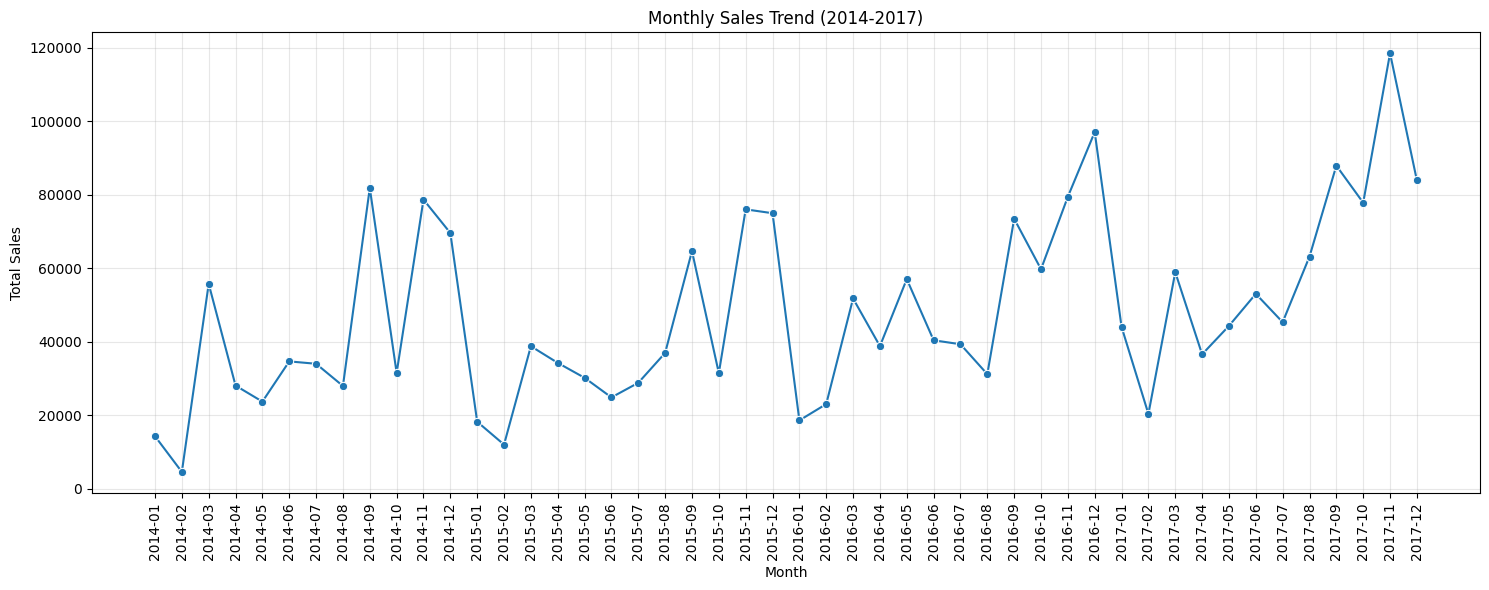

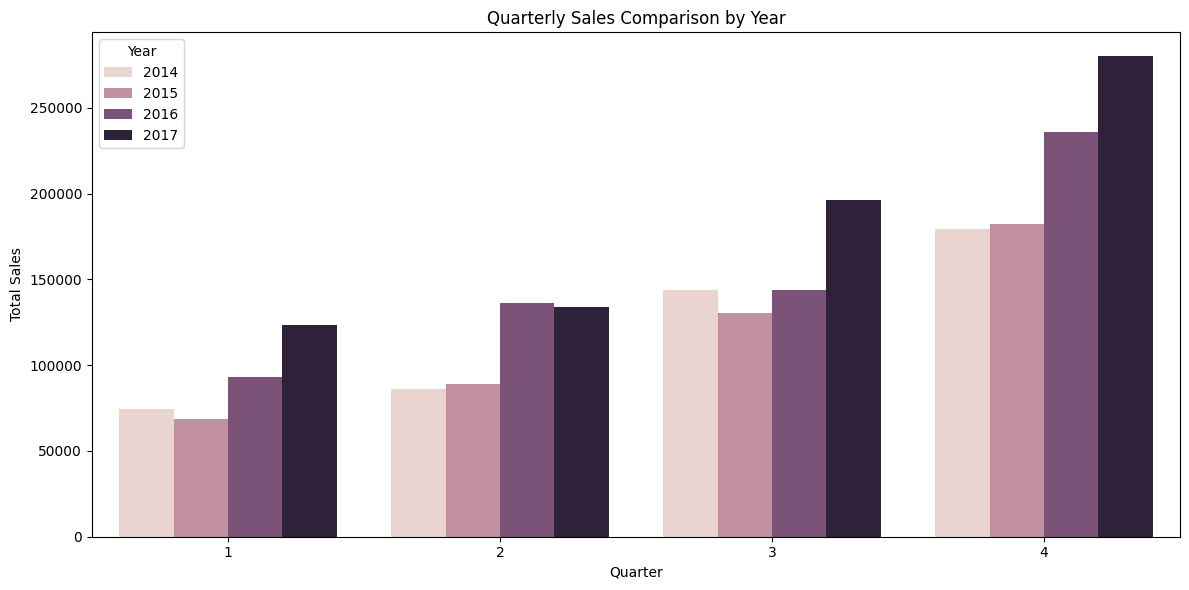

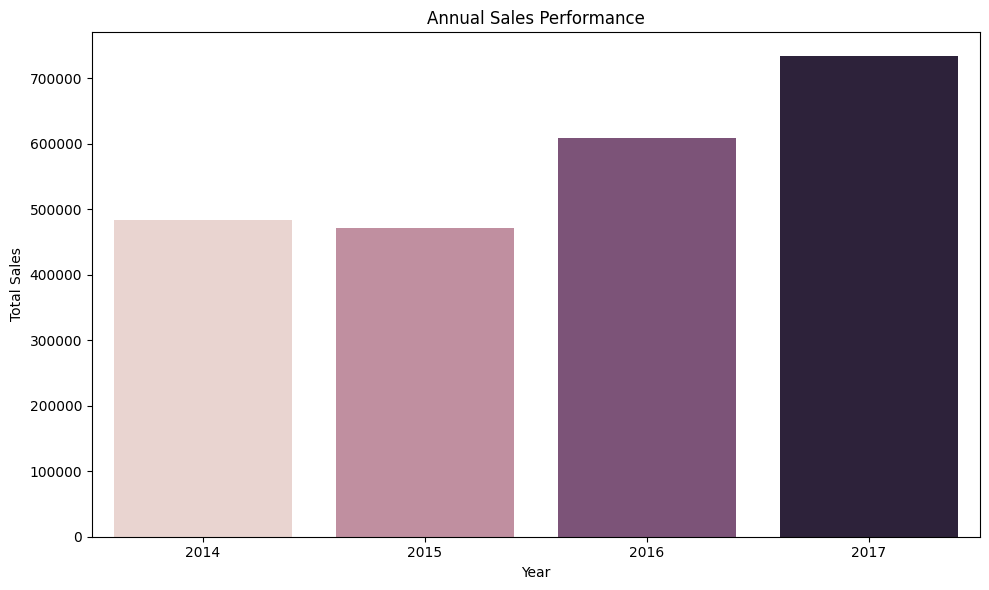

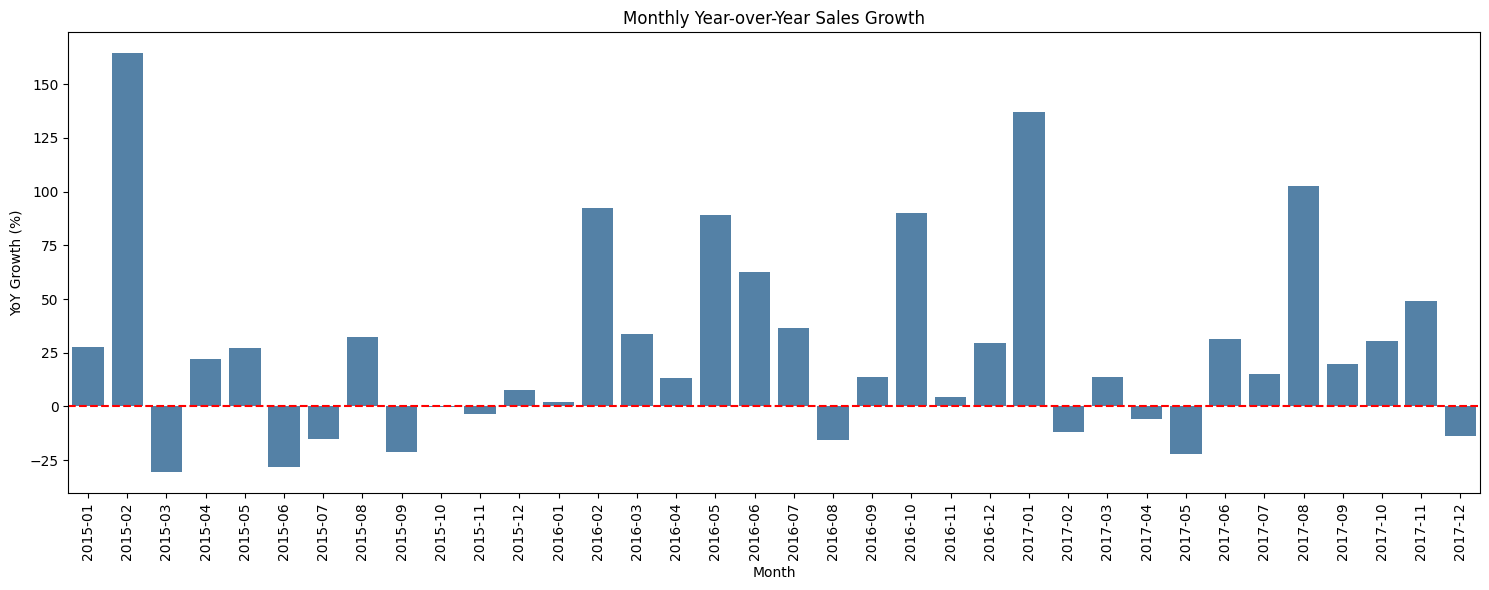


========== FINAL BUSINESS INSIGHTS ==========
Best Sales Month: 2017-11 | Sales: 118447.82
Best Performing Quarter: 2017-Q4 | Sales: 280054.07
Best Performing Year: 2017 | Sales: 733215.26
Average Monthly Sales: 47852.49
Overall Sales: 2296919.49


In [28]:
# 1. QUARTERLY SALES SUMMARY

quarterly_sales = (
    time_df.groupby(["Year", "Quarter"])["Daily_Sales"]
    .sum()
    .reset_index()
)

quarterly_sales["Year_Quarter"] = (
    quarterly_sales["Year"].astype(str)
    + "-Q"
    + quarterly_sales["Quarter"].astype(str)
)

# 2. LATEST DATE KPI SUMMARY

latest_date = time_df["Date"].max()

latest_kpi = time_df.loc[
    time_df["Date"] == latest_date
].iloc[0]

print("========== LATEST SALES KPIs ==========")

print("Latest Available Date:", latest_date.date())

print("Latest MTD Sales:", round(latest_kpi["MTD_Sales"], 2))

print("Latest QTD Sales:", round(latest_kpi["QTD_Sales"], 2))

print("Latest YTD Sales:", round(latest_kpi["YTD_Sales"], 2))


# 3. ANNUAL GROWTH SUMMARY

yearly_sales["Previous_Year_Sales"] = (
    yearly_sales["Monthly_Sales"].shift(1)
)

yearly_sales["YoY_Growth_%"] = (
    (
        yearly_sales["Monthly_Sales"]
        - yearly_sales["Previous_Year_Sales"]
    )
    / yearly_sales["Previous_Year_Sales"]
) * 100

print("\nANNUAL SALES GROWTH:")
display(yearly_sales)


# 4. MONTHLY SALES TREND

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_sales,
    x="Year_Month",
    y="Monthly_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend (2014-2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 5. QUARTERLY SALES COMPARISON

plt.figure(figsize=(12, 6))

sns.barplot(
    data=quarterly_sales,
    x="Quarter",
    y="Daily_Sales",
    hue="Year",
    estimator="sum",
    errorbar=None
)

plt.title("Quarterly Sales Comparison by Year")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.legend(title="Year")
plt.tight_layout()
plt.show()


# 6. YEARLY SALES COMPARISON

plt.figure(figsize=(10, 6))

sns.barplot(
    data=yearly_sales,
    x="Year",
    y="Monthly_Sales",
    hue="Year",
    legend=False
)

plt.title("Annual Sales Performance")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


# 7. MONTHLY YOY GROWTH

yoy_plot_df = monthly_sales.dropna(
    subset=["YoY_Growth_%"]
).copy()

plt.figure(figsize=(15, 6))

sns.barplot(
    data=yoy_plot_df,
    x="Year_Month",
    y="YoY_Growth_%",
    color="steelblue"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Monthly Year-over-Year Sales Growth")
plt.xlabel("Month")
plt.ylabel("YoY Growth (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# 8. FINAL BUSINESS INSIGHTS

best_month = monthly_sales.loc[
    monthly_sales["Monthly_Sales"].idxmax()
]

best_quarter = quarterly_sales.loc[
    quarterly_sales["Daily_Sales"].idxmax()
]

best_year = yearly_sales.loc[
    yearly_sales["Monthly_Sales"].idxmax()
]

print("\n========== FINAL BUSINESS INSIGHTS ==========")

print(
    "Best Sales Month:",
    best_month["Year_Month"],
    "| Sales:",
    round(best_month["Monthly_Sales"], 2)
)

print(
    "Best Performing Quarter:",
    best_quarter["Year_Quarter"],
    "| Sales:",
    round(best_quarter["Daily_Sales"], 2)
)

print(
    "Best Performing Year:",
    int(best_year["Year"]),
    "| Sales:",
    round(best_year["Monthly_Sales"], 2)
)

print(
    "Average Monthly Sales:",
    round(monthly_sales["Monthly_Sales"].mean(), 2)
)

print(
    "Overall Sales:",
    round(df["Sales"].sum(), 2)
)